# UTHz Modulation Simulation Framework: photomixing THz link with antenna gains

A THz-only revision of the unified UTHz/UOWC notebook. One end-to-end model of a **photonic (photomixing) THz link** at
**0.1 THz and 0.3 THz**, with **transmit and receive antenna gains** as explicit, tunable inputs, compared across
**4-QAM, 8-QAM, 16-QAM, 64-QAM and PAM**.

**What changed compared with the original notebook**

| Item | Original | This notebook |
|---|---|---|
| Domains | UTHz + UOWC | **UTHz only** (UOWC removed) |
| Carrier | one wavelength, 1 mm (hard-coded) | **0.1 THz (3 mm) and 0.3 THz (1 mm)**, wavelength computed from frequency |
| Transmit power | 100 W | **20 mW** (13.0 dBm), photonic photomixing source |
| Antennas | none | **Tx gain and Rx gain** (dBi), set directly or derived from a **2 cm x 1.5 cm** aperture |
| Attenuation | `alpha = 12 300 1/m` | **unchanged** (same `exp(alpha*d)` power law, applied at both frequencies) |
| Modulation | OOK, QPSK, OFDM | **4-QAM, 8-QAM, 16-QAM, 64-QAM, 4-PAM** |
| BER theory | hand-set constants | **general Gray-coded formulas** for rectangular QAM and PAM (fixes the 8/16-QAM mismatch noted in the old section 9) |

**Link budget (dB form):**

`Pr = Pt + G_tx + G_rx - FSPL(f, d) - 4.343 * alpha * d`

| § | Content |
|---|---|
| 1 | Configuration (every knob lives here) |
| 2 | Antenna gain from aperture, far-field and near-field limits |
| 3 | Modulation scheme registry (constellations + theoretical BER) |
| 4 | Channel model and link budget |
| 5 | Simulation engine (bit-level Monte-Carlo) |
| 6 | Energy and transmission-time profile |
| 7 | Parameter sweeps: BER vs SNR / distance / data rate / received power |
| 8 | Link characteristics: path loss, received power, Shannon limit |
| 9 | Received constellations and eye diagrams |
| 10 | Simulation vs theory validation |
| 11 | Consolidated summary table |
| 12 | **Antenna-gain study** (SNR, BER, maximum range vs gain) |

**Run order:** top to bottom (*Run all*). Total runtime is roughly 1 to 3 minutes (section 10 is the heavy one).

> **Read this before trusting any number.** The Friis formula is a *far-field* result. With a notebook attenuation of
> about 53 dB per millimetre, the link only exists at sub-millimetre to few-millimetre distances, which is *inside* the
> far-field distance of any real horn. Wherever `FSPL < G_tx + G_rx` the formula predicts **more power received than
> transmitted**, which is impossible for a passive link. Every distance plot therefore marks that region
> ("Friis not valid") so you can see which part of a curve is physical.

## 1. Configuration
Single source of truth. Change a value here and every table and plot downstream updates.
The values you are most likely to play with are `LEGACY_GAINS` (antenna gains per frequency), `GAIN_STUDY_DBI`, `NOISE_MODE` and `PAM_BITS`.
The link budget and the modulation engine live in `dwf2d/channels.py` (shared with the DWF); this notebook imports them.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import upfirdn
from scipy.special import erfc
import os, sys
sys.path.insert(0, os.path.abspath(""))         # advanced_DWF/: the link and modulation code is imported from dwf2d
from dwf2d import channels as ch

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.35,
                     "axes.spines.top": False, "axes.spines.right": False})

# --- Reproducibility --------------------------------------------------------
SEED = 42
rng = np.random.default_rng(SEED)

# --- Physical constants -----------------------------------------------------
C   = 3e8                 # speed of light (m/s)
K_B = 1.380649e-23        # Boltzmann constant (J/K)

# --- Transmitter / signal ---------------------------------------------------
PT_W               = 20e-3                 # Transmit power: 20 mW from a photonic photomixer
PT_DBW             = 10 * np.log10(PT_W)   # = -17.0 dBW  (= +13.0 dBm)
R_s                = 1e9                   # Symbol rate (1 Gsps), also taken as the noise bandwidth
sps                = 4                     # Samples per symbol for pulse shaping
rrc_rolloff        = 0.35                  # Root-raised-cosine roll-off (shared TX/RX pulse filter)
rrc_span           = 8                     # RRC filter span in symbols (taps = span * sps + 1)
num_symbols        = 10_000                # Symbols per Monte-Carlo run (constellation / eye plots)
num_symbols_ber    = 200_000               # Symbols per point in the BER validation (section 10)
payload_size_bytes = 8 * 1024 * 1024       # 8 MB benchmark payload

# --- Carrier frequencies ----------------------------------------------------
FREQS_HZ = {"0.1 THz": 0.1e12, "0.3 THz": 0.3e12}      # wavelengths 3 mm and 1 mm

# --- Antennas ---------------------------------------------------------------
APERTURE_A_M        = 0.020      # horn aperture, 2 cm
APERTURE_B_M        = 0.015      # horn aperture, 1.5 cm
APERTURE_EFFICIENCY = 0.51       # aperture efficiency (same value as the horn-antenna script)

#   Antenna gains are set PER FREQUENCY (ch.GAIN_DBI_BY_FREQ): 0.1 THz -> 5 dBi each end, 0.3 THz -> 10 dBi each end.
#   LEGACY_GAINS = True uses 5 dBi at both ends at BOTH frequencies (reproduces the earlier saved outputs).
LEGACY_GAINS = False
GAINS_DBI = {fname: ch.preset_gains(f, LEGACY_GAINS) for fname, f in FREQS_HZ.items()}   # (G_tx, G_rx) per frequency

def gains(fname):
    """(G_tx, G_rx) in dBi used in the main sections for carrier `fname`."""
    return GAINS_DBI[fname]

def gains_hz(freq_hz):
    """(G_tx, G_rx) in dBi for a carrier given in Hz (one of FREQS_HZ)."""
    return next(GAINS_DBI[n] for n, f in FREQS_HZ.items() if f == freq_hz)

def gain_label():
    """Gain text for figure titles: one pair if both frequencies share it, else one pair per frequency."""
    if len(set(GAINS_DBI.values())) == 1:
        g_tx, g_rx = next(iter(GAINS_DBI.values()))
        return f"G_tx = {g_tx:g} dBi, G_rx = {g_rx:g} dBi"
    return ", ".join(f"{n}: G_tx/G_rx = {gt:g}/{gr:g} dBi" for n, (gt, gr) in GAINS_DBI.items())

GAIN_STUDY_DBI = [0, 5, 10, 20, 40]    # gains compared in the section-12 study (applied at both ends)

# --- THz channel (attenuation kept exactly as in the original notebook) ------
ALPHA_THZ = 12300.0              # Molecular extinction coefficient (1/m), power law exp(alpha*d)

# --- Receiver noise ---------------------------------------------------------
#  "thermal"  : N0 = k*T*F  (F = noise figure), noise power = N0 * R_s   (physically motivated)
#  "notebook" : the original fixed values (1 mW noise floor, 1e-10 W/Hz PSD)
NOISE_MODE      = "thermal"
T_NOISE_K       = 290.0
NOISE_FIGURE_DB = 10.0
NOTEBOOK_NOISE_FLOOR_W = 1e-3
NOTEBOOK_NOISE_PSD     = 1e-10

if NOISE_MODE == "thermal":
    NOISE_PSD_W_HZ = ch.noise_psd_w_hz(T_NOISE_K, NOISE_FIGURE_DB)    # W/Hz, k_B * T * 10^(NF/10)
    NOISE_FLOOR_W  = NOISE_PSD_W_HZ * R_s                              # W in the symbol bandwidth
else:
    NOISE_PSD_W_HZ = NOTEBOOK_NOISE_PSD
    NOISE_FLOOR_W  = NOTEBOOK_NOISE_FLOOR_W
NOISE_FLOOR_DBW = 10 * np.log10(NOISE_FLOOR_W)

# --- Distances --------------------------------------------------------------
D_REF_M  = 0.1e-3                # Reference distance (0.1 mm), same as the original notebook
DEMO_TARGET_SNR_DB = 20.0        # Demo distance = where the link budget gives this Es/N0 (per frequency)
D_DEMO_OVERRIDE_M  = {}          # e.g. {"0.1 THz": 1.5e-3} to force a demo distance instead
DIST_SWEEP_M = np.linspace(0.01, 3.0, 400) * 1e-3     # 0.01 .. 3 mm

# --- Sweep ranges -----------------------------------------------------------
snr_db_range       = np.linspace(0, 30, 300)                       # BER vs Es/N0 (dB)
p_rec_sweep_dbw    = np.linspace(NOISE_FLOOR_DBW - 5, NOISE_FLOOR_DBW + 40, 300)   # BER vs received power (dBW)
data_rates_sweep   = np.logspace(8, 11.3, 200)                     # 100 Mbps .. 200 Gbps
ebn0_validation_db = np.arange(0, 21, 2)                           # Eb/N0 grid for simulation vs theory

# --- Scheme / plotting choices ---------------------------------------------
PAM_BITS       = 2               # 2 -> 4-PAM, 1 -> 2-PAM, 3 -> 8-PAM
EYE_SCHEMES    = ["4-QAM", "16-QAM"]   # schemes shown as eye diagrams
BER_TARGET     = 1e-3            # BER used to define "maximum range"
HEATMAP_SCHEME = "16-QAM"        # scheme used in the (G_tx, G_rx) range heat-map

print(f"Pt = {PT_W*1e3:.0f} mW = {PT_DBW:.2f} dBW = {PT_DBW+30:.2f} dBm")
print(f"Noise mode: {NOISE_MODE}  ->  N0 = {NOISE_PSD_W_HZ:.2e} W/Hz,  noise floor = {NOISE_FLOOR_W:.2e} W = {NOISE_FLOOR_DBW:.1f} dBW")
print(f"Absorption: {10*np.log10(np.e)*ALPHA_THZ/1e3:.1f} dB per mm  (alpha = {ALPHA_THZ:g} 1/m)")

Pt = 20 mW = -16.99 dBW = 13.01 dBm
Noise mode: thermal  ->  N0 = 4.00e-20 W/Hz,  noise floor = 4.00e-11 W = -104.0 dBW
Absorption: 53.4 dB per mm  (alpha = 12300 1/m)


## 2. Antenna gain, far-field and near-field limits
For an aperture antenna of area `A = a x b` and efficiency `eta`:

`G = 4 pi eta A / lambda^2`  (linear), `G_dBi = 10 log10(G)`

Two distances matter:

* **Far-field distance** `2 D^2 / lambda` (`D` = aperture diagonal): the classical start of the region where the
  Friis equation is valid for *those* horns.
* **Friis consistency limit** `d_nf = lambda/(4 pi) * 10^((G_tx+G_rx)/20)`: the distance at which the free-space
  spreading loss `FSPL` equals `G_tx + G_rx`. Closer than this the formula gives `Pr > Pt` (an unphysical net gain).
  Given the gains you choose, this is the number that decides which part of each plot is trustworthy.

In [36]:
# Geometry functions: dwf2d/channels.py (moved verbatim), bound here to this notebook's aperture settings.
wavelength = ch.wavelength                       # Free-space wavelength (m)
near_field_limit_m = ch.near_field_limit_m       # Distance where FSPL = G_tx + G_rx (Friis consistency limit)

def aperture_gain_dbi(freq_hz, a_m=APERTURE_A_M, b_m=APERTURE_B_M, eta=APERTURE_EFFICIENCY):
    """Gain (dBi) of an a x b aperture antenna: G = 4*pi*eta*A / lambda^2."""
    return ch.aperture_gain_dbi(freq_hz, a_m, b_m, eta)

def far_field_distance_m(freq_hz, a_m=APERTURE_A_M, b_m=APERTURE_B_M):
    """Classical far-field distance 2*D^2/lambda, D = aperture diagonal."""
    return ch.far_field_distance_m(freq_hz, a_m, b_m)

# Table: gain of several aperture sizes at both frequencies
apertures = [("2 cm x 1.5 cm (this study)", 0.02, 0.015), ("5 mm x 5 mm", 0.005, 0.005),
             ("2 mm x 2 mm", 0.002, 0.002), ("1 mm x 1 mm", 0.001, 0.001)]
rows = []
for fname, f in FREQS_HZ.items():
    for label, a, b in apertures:
        g = aperture_gain_dbi(f, a, b)
        rows.append({"Frequency": fname, "Wavelength (mm)": wavelength(f) * 1e3, "Aperture": label,
                     "Gain (dBi)": g, "Far-field 2D^2/lambda (mm)": far_field_distance_m(f, a, b) * 1e3,
                     "Friis limit, equal gains (mm)": near_field_limit_m(f, g, g) * 1e3})
df_antenna = pd.DataFrame(rows)
display(df_antenna.round(2))

print("\nGains used in the main sections:")
for fname, f in FREQS_HZ.items():
    g_tx, g_rx = gains(fname)
    print(f"  {fname}: G_tx = {g_tx:g} dBi, G_rx = {g_rx:g} dBi  ->  Friis valid beyond "
          f"{near_field_limit_m(f, g_tx, g_rx)*1e3:.2f} mm   "
          f"(2 cm x 1.5 cm horn would give {aperture_gain_dbi(f):.1f} dBi)")

,Frequency,Wavelength (mm),Aperture,Gain (dBi),Far-field 2D^2/lambda (mm),"Friis limit, equal gains (mm)"
0,0.1 THz,3.0,2 cm x 1.5 cm (this study),23.30,416.67,51.00
1,0.1 THz,3.0,5 mm x 5 mm,12.50,33.33,4.25
2,0.1 THz,3.0,2 mm x 2 mm,4.55,5.33,0.68
3,0.1 THz,3.0,1 mm x 1 mm,-1.47,1.33,0.17
4,0.3 THz,1.0,2 cm x 1.5 cm (this study),32.84,1250.00,153.00
5,0.3 THz,1.0,5 mm x 5 mm,22.05,100.00,12.75
6,0.3 THz,1.0,2 mm x 2 mm,14.09,16.00,2.04
7,0.3 THz,1.0,1 mm x 1 mm,8.07,4.00,0.51



Gains used in the main sections:
  0.1 THz: G_tx = 5 dBi, G_rx = 5 dBi  ->  Friis valid beyond 0.75 mm   (2 cm x 1.5 cm horn would give 23.3 dBi)
  0.3 THz: G_tx = 5 dBi, G_rx = 5 dBi  ->  Friis valid beyond 0.25 mm   (2 cm x 1.5 cm horn would give 32.8 dBi)


## 3. Modulation scheme registry
Every scheme carries its constellation (`points`, indexed by **bit label**, Gray-coded on each axis) and its
theoretical BER as a function of **Eb/N0**.

**Schemes:** 4-QAM (the "QAM" of the brief; identical to QPSK), 8-QAM (4 x 2 rectangular), 16-QAM, 64-QAM, and M-PAM
(real, bipolar levels, as in the original `gray_pam`; `PAM_BITS` sets M).

**Theory (Gray labelling, nearest-neighbour approximation, per-axis levels `L_I`, `L_Q`, `k = log2 M`):**

`BER_QAM = (1/k) * [(1 - 1/L_I) + (1 - 1/L_Q)] * erfc( sqrt( 3k / ((L_I^2-1) + (L_Q^2-1)) * Eb/N0 ) )`

`BER_PAM = (1/k) * (1 - 1/L) * erfc( sqrt( 3k / (L^2-1) * Eb/N0 ) )`

These reduce to the textbook values: 4-QAM `0.5 erfc(sqrt(Eb/N0))`, 16-QAM `0.375 erfc(sqrt(0.4 Eb/N0))`.
(The original notebook's 8/16-QAM entries were off by 1.5 to 3 dB: its 16-QAM exponent `0.8` should be `0.4`.)

**Note:** 16-QAM is two independent 4-PAM streams, so **16-QAM and 4-PAM have identical BER vs Eb/N0**. They only differ on axes where the SNR-to-Eb/N0 conversion depends on bits per symbol. Where they coincide (data-rate sweep, validation) 4-PAM is drawn dashed so both stay visible.

In [37]:
# Constellations and theoretical BER: dwf2d/channels.py (moved verbatim from this cell).
from dwf2d.channels import gray_pam, gray_qam, qam_ber_theory, pam_ber_theory, make_scheme

PAM_NAME = f"{2 ** PAM_BITS}-PAM"
SCHEMES = {
    "4-QAM":  make_scheme("4-QAM",  2, gray_qam(1, 1), qam_ber_theory(1, 1)),
    "8-QAM":  make_scheme("8-QAM",  3, gray_qam(2, 1), qam_ber_theory(2, 1)),
    "16-QAM": make_scheme("16-QAM", 4, gray_qam(2, 2), qam_ber_theory(2, 2)),
    "64-QAM": make_scheme("64-QAM", 6, gray_qam(3, 3), qam_ber_theory(3, 3)),
    PAM_NAME: make_scheme(PAM_NAME, PAM_BITS, gray_pam(PAM_BITS), pam_ber_theory(PAM_BITS)),
}
SCHEME_COLORS = {name: plt.cm.tab10(i) for i, name in enumerate(SCHEMES)}   # one fixed colour per scheme
SCHEME_LS = {name: ((0, (5, 2)) if name == PAM_NAME else "-") for name in SCHEMES}   # PAM dashed (it coincides with 16-QAM vs Eb/N0)
SCHEME_MARK = {name: ("s" if name == PAM_NAME else "o") for name in SCHEMES}

print(f"{'Scheme':8s} {'bits/sym':>8s} {'avg power':>10s}  1-D?")
for s in SCHEMES.values():
    print(f"{s['name']:8s} {s['bits_per_symbol']:>8d} {s['avg_power']:>10.3f}  {s['is_one_dim']}")

Scheme   bits/sym  avg power  1-D?
4-QAM           2      1.000  False
8-QAM           3      1.000  False
16-QAM          4      1.000  False
64-QAM          6      1.000  False
4-PAM           2      5.000  True


## 4. Channel model and link budget
All quantities in dB (`FSPL` from the closed form, absorption from the notebook's `alpha`):

* `FSPL(f, d) = 20 log10(4 pi d f / c)`
* `Absorption(d) = 10 log10(e) * alpha * d`  (= 53.4 dB per mm for `alpha = 12 300 1/m`)
* **Coupling loss** `= FSPL + Absorption - G_tx - G_rx` : the total power lost between the Tx input and the Rx output.
  A *negative* coupling loss means `Pr > Pt`, which is unphysical and only appears where the Friis formula is invalid.
* `Pr = Pt - coupling loss`, and `SNR (Es/N0) = Pr / noise_floor`, where the noise floor is `N0 * R_s`.

`link_budget` is the **only** place SNR is derived from geometry, and every later section calls it.
The *demo distance* of each frequency is the distance at which the budget gives `DEMO_TARGET_SNR_DB`; it is solved here rather than hard-coded.

In [38]:
# Link budget: dwf2d/channels.py (moved verbatim); bound here to this notebook's Pt, noise floor, alpha and gains.
fspl_db = ch.fspl_db                              # Free-space path loss (dB)

def absorption_db(d_m):
    """Molecular/absorption loss (dB) from exp(alpha*d) on power."""
    return ch.absorption_db(d_m, ALPHA_THZ)

def _resolve(freq_hz, g_tx_dbi, g_rx_dbi):
    g_tx, g_rx = gains_hz(freq_hz)
    return (g_tx if g_tx_dbi is None else g_tx_dbi), (g_rx if g_rx_dbi is None else g_rx_dbi)

def link_budget(freq_hz, d_m, g_tx_dbi=None, g_rx_dbi=None, p_tx_w=None, noise_floor_w=None):
    """Full link budget at distance d (scalar or array); gains default to this frequency's GAINS_DBI."""
    g_tx, g_rx = _resolve(freq_hz, g_tx_dbi, g_rx_dbi)
    return ch.link_budget(freq_hz, d_m, g_tx, g_rx, PT_W if p_tx_w is None else p_tx_w,
                          NOISE_FLOOR_W if noise_floor_w is None else noise_floor_w, alpha=ALPHA_THZ)

def solve_distance_for_snr(freq_hz, target_snr_db, g_tx_dbi=None, g_rx_dbi=None):
    """Distance (m) at which the budget gives the target SNR (SNR falls monotonically with d)."""
    g_tx, g_rx = _resolve(freq_hz, g_tx_dbi, g_rx_dbi)
    return ch.solve_distance_for_snr(freq_hz, target_snr_db, g_tx, g_rx,
                                     p_tx_w=PT_W, noise_floor_w=NOISE_FLOOR_W, alpha=ALPHA_THZ)

# Demo distance per frequency
D_DEMO_M = {}
for fname, f in FREQS_HZ.items():
    d = D_DEMO_OVERRIDE_M.get(fname, solve_distance_for_snr(f, DEMO_TARGET_SNR_DB))
    if not np.isfinite(d):
        d = 0.4e-3
        print(f"Warning: {fname} cannot reach {DEMO_TARGET_SNR_DB} dB SNR; falling back to {d*1e3} mm")
    D_DEMO_M[fname] = d

# Link-budget table at the reference and demo distances
budget_rows = []
for fname, f in FREQS_HZ.items():
    for label, d in (("reference", D_REF_M), ("demo", D_DEMO_M[fname])):
        b = link_budget(f, d)
        budget_rows.append({"Frequency": fname, "Point": label, "Distance (mm)": d * 1e3,
                            "FSPL (dB)": b["fspl_db"], "Absorption (dB)": b["absorption_db"],
                            "G_tx+G_rx (dB)": sum(gains(fname)), "Coupling loss (dB)": b["coupling_loss_db"],
                            "Pr (dBW)": b["pr_dbw"], "Pr (dBm)": b["pr_dbw"] + 30, "SNR (dB)": b["snr_db"],
                            "Friis valid?": "no (Pr > Pt)" if b["friis_invalid"] else "yes"})
df_budget = pd.DataFrame(budget_rows)
display(df_budget.round(2))

,Frequency,Point,Distance (mm),FSPL (dB),Absorption (dB),G_tx+G_rx (dB),Coupling loss (dB),Pr (dBW),Pr (dBm),SNR (dB),Friis valid?
0,0.1 THz,reference,0.10,-7.56,5.34,10.0,-12.22,-4.77,25.23,99.20,no (Pr > Pt)
1,0.1 THz,demo,1.18,13.89,63.10,10.0,66.99,-83.98,-53.98,20.00,yes
2,0.3 THz,reference,0.10,1.98,5.34,10.0,-2.67,-14.32,15.68,89.66,no (Pr > Pt)
3,0.3 THz,demo,1.03,22.20,54.78,10.0,66.99,-83.98,-53.98,20.00,yes


## 5. Simulation engine
`simulate_link` runs the full chain for one scheme at a requested symbol-domain SNR (Es/N0):
bits -> Gray-labelled symbols -> zero-stuffed upsampling and pulse shaping -> AWGN -> matched filter -> sampling at the
decision instants -> minimum-distance decoding -> BER.

Transmit and receive share one **root-raised-cosine** pulse of unit energy, so the matched-filter output at the decision
instant equals the transmitted symbol and the noise keeps variance `N0`. The absolute received power cancels out of the
decision statistic, so SNR is passed in directly; the link budget (section 4) supplies it.
Decoding is done in chunks so that 64-QAM at 200 000 symbols stays light on memory.

In [39]:
# Simulation engine: dwf2d/channels.py (moved verbatim). The factory binds the RRC pulse, its delay and the
# seeded rng, so the draws happen in the same order as before.
from dwf2d.channels import rrc_pulse, min_distance_decode
simulate_link = ch.make_link_simulator(rrc_rolloff, rrc_span, sps, rng, num_symbols)
PULSE, DELAY = simulate_link.PULSE, simulate_link.DELAY      # unit-energy RRC pulse; TX + RX group delay (samples)

# quick self-test: 4-QAM at 10 dB Es/N0 (Eb/N0 = 7 dB) should be close to theory
_t = simulate_link(SCHEMES["4-QAM"], 10.0, n_symbols=100_000)
print(f"self-test 4-QAM @ Es/N0 = 10 dB: simulated BER = {_t['ber']:.2e}, "
      f"theory = {float(SCHEMES['4-QAM']['ber_func'](10 ** (10 / 10) / 2)):.2e}")

self-test 4-QAM @ Es/N0 = 10 dB: simulated BER = 8.55e-04, theory = 7.83e-04


## 6. Energy and transmission-time profile
Time and energy to move the 8 MB payload at `R_s x bits_per_symbol`, with the 20 mW transmit power held constant.

In [40]:
payload_bits = payload_size_bytes * 8

energy_rows = []
for cfg in SCHEMES.values():
    rate = R_s * cfg["bits_per_symbol"]
    duration = payload_bits / rate
    energy_rows.append({"Modulation": cfg["name"], "Bits/Symbol": cfg["bits_per_symbol"],
                        "Data Rate (Gbps)": rate / 1e9, "Duration (ms)": duration * 1e3,
                        "Energy Spent (mJ)": PT_W * duration * 1e3})
df_energy = pd.DataFrame(energy_rows)
display(df_energy.round(3))

,Modulation,Bits/Symbol,Data Rate (Gbps),Duration (ms),Energy Spent (mJ)
0,4-QAM,2,2.0,33.554,0.671
1,8-QAM,3,3.0,22.370,0.447
2,16-QAM,4,4.0,16.777,0.336
3,64-QAM,6,6.0,11.185,0.224
4,4-PAM,2,2.0,33.554,0.671


## 7. Parameter sweeps (BER vs SNR / distance / data rate / received power)
Each figure has one column per carrier frequency and one curve per scheme. Theoretical BER is evaluated from `Eb/N0`.

* **SNR sweep:** `Es/N0` is swept directly; `Eb/N0 = Es/N0 / k`.
* **Distance sweep:** `Es/N0` from the link budget (default gains). Grey shading marks where `FSPL < G_tx + G_rx` (Friis not valid); the dotted line is the demo distance.
* **Data-rate sweep:** noise power grows with the bit rate, `Eb/N0 = Pr / (N0 R_b)` at the demo distance. (The original notebook divided by `k` again here, which double-counted the bits per symbol.)
* **Received-power sweep:** `Es/N0 = Pr / noise_floor`, with the swept power range centred on the noise floor.

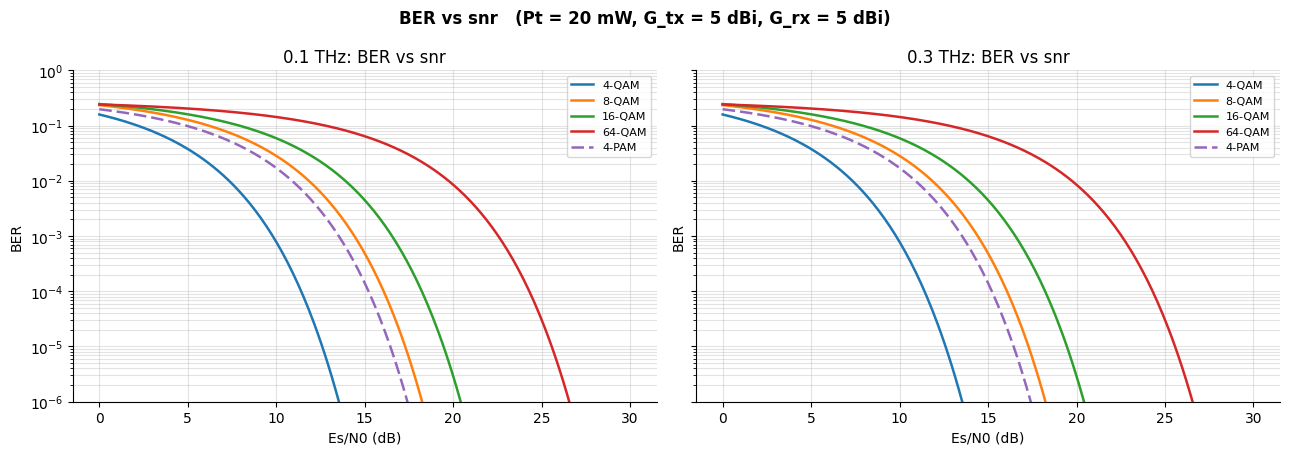

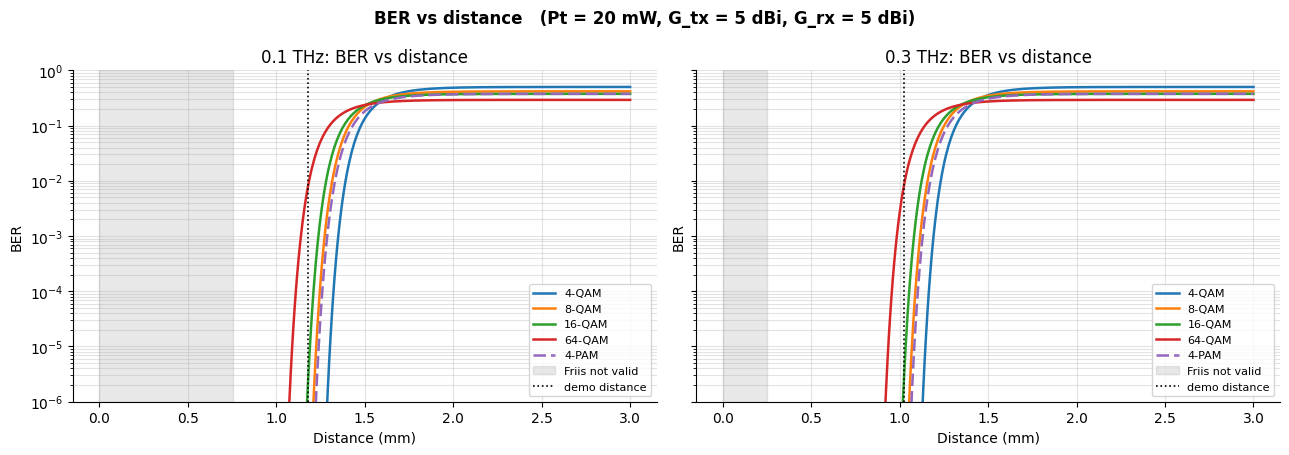

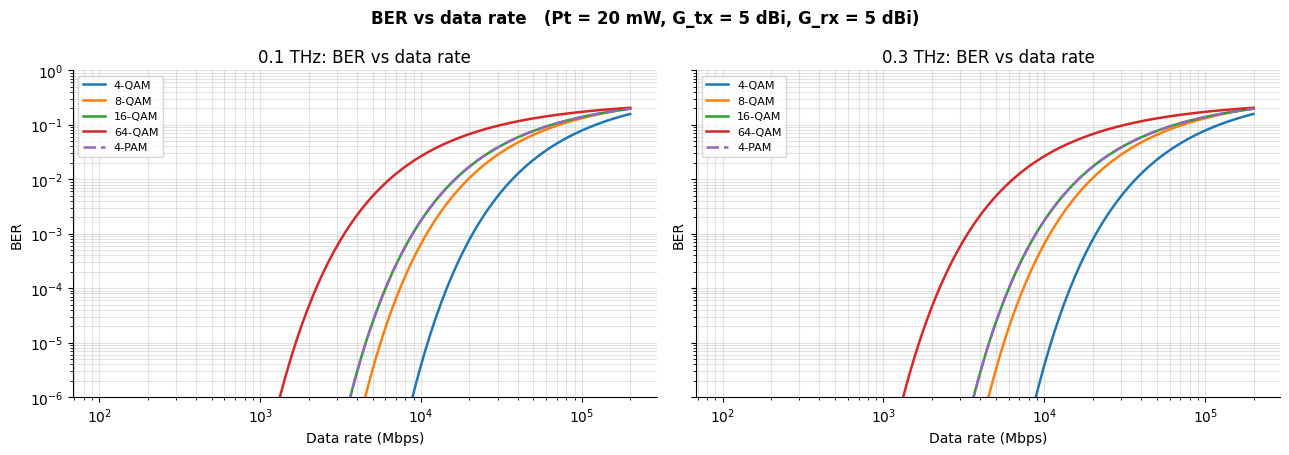

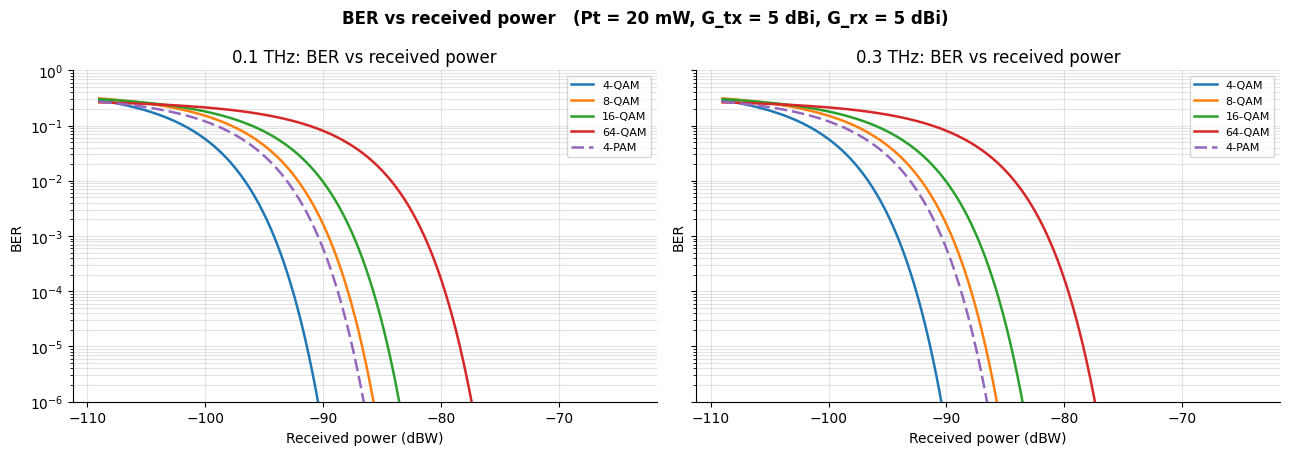

In [41]:
snr_lin_range = 10 ** (snr_db_range / 10)
p_rec_lin     = 10 ** (p_rec_sweep_dbw / 10)
SWEEP_ORDER = ["SNR", "Distance", "Data Rate", "Received Power"]

def make_sweeps(fname):
    """SWEEPS[freq][sweep] = (x, ebn0_fn(k), xlabel, xscale)."""
    f = FREQS_HZ[fname]
    snr_dist = link_budget(f, DIST_SWEEP_M)["snr"]
    pr_demo  = link_budget(f, D_DEMO_M[fname])["pr_w"]
    return {
        "SNR":            (snr_db_range,           lambda k: snr_lin_range / k,                       "Es/N0 (dB)",           "linear"),
        "Distance":       (DIST_SWEEP_M * 1e3,     lambda k: snr_dist / k,                            "Distance (mm)",        "linear"),
        "Data Rate":      (data_rates_sweep / 1e6, lambda k: pr_demo / (NOISE_PSD_W_HZ * data_rates_sweep), "Data rate (Mbps)", "log"),
        "Received Power": (p_rec_sweep_dbw,        lambda k: p_rec_lin / NOISE_FLOOR_W / k,           "Received power (dBW)", "linear"),
    }

SWEEPS = {fname: make_sweeps(fname) for fname in FREQS_HZ}

def plot_ber_curves(ax, fname, sweep):
    x, ebn0_fn, xlabel, xscale = SWEEPS[fname][sweep]
    for name, cfg in SCHEMES.items():
        ax.plot(x, cfg["ber_func"](ebn0_fn(cfg["bits_per_symbol"])), lw=1.8, ls=SCHEME_LS[name], color=SCHEME_COLORS[name], label=name)
    if sweep == "Distance":
        d_nf = near_field_limit_m(FREQS_HZ[fname], *gains(fname)) * 1e3
        ax.axvspan(0, min(d_nf, x.max()), color="grey", alpha=0.18, label="Friis not valid")
        ax.axvline(D_DEMO_M[fname] * 1e3, color="k", ls=":", lw=1.2, label="demo distance")
    ax.set(xscale=xscale, yscale="log", ylim=(1e-6, 1), xlabel=xlabel, ylabel="BER",
           title=f"{fname}: BER vs {sweep.lower()}")
    ax.grid(True, which="both")
    ax.legend(fontsize=8)

for sweep in SWEEP_ORDER:
    fig, axes = plt.subplots(1, len(FREQS_HZ), figsize=(6.5 * len(FREQS_HZ), 4.6), sharey=True)
    for ax, fname in zip(axes, FREQS_HZ):
        plot_ber_curves(ax, fname, sweep)
    fig.suptitle(f"BER vs {sweep.lower()}   (Pt = {PT_W*1e3:.0f} mW, {gain_label()})",
                 fontweight="bold")
    plt.tight_layout()
    plt.show()

## 8. Link characteristics
* **Left:** coupling loss and received power vs distance for both frequencies (received power on the right axis). Grey dashed segments are where `FSPL < G_tx + G_rx`: the loss goes *negative* and `Pr > Pt` (unphysical).
* **Centre:** the three loss components at the demo frequencies (FSPL, absorption, antenna gain) so you can see what dominates: absorption wins almost immediately.
* **Right:** Shannon limit `B log2(1 + SNR)` with `B = R_s`, with the raw bit rate of every scheme drawn as a horizontal line.

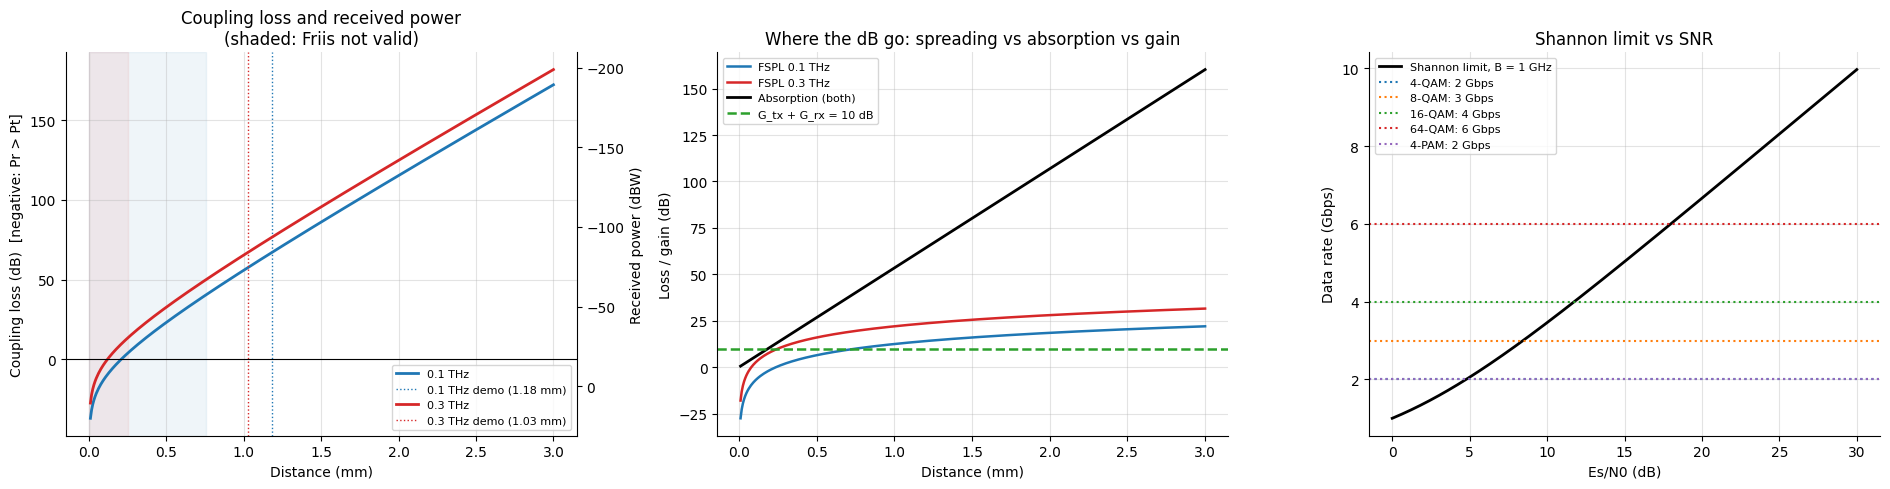

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
freq_ls = {"0.1 THz": "-", "0.3 THz": "--"}
freq_col = {"0.1 THz": "tab:blue", "0.3 THz": "tab:red"}

# (1) coupling loss and received power
ax = axes[0]
for fname, f in FREQS_HZ.items():
    b = link_budget(f, DIST_SWEEP_M)
    x = DIST_SWEEP_M * 1e3
    ax.plot(x, b["coupling_loss_db"], color=freq_col[fname], ls="-", lw=2, label=f"{fname}")
    ax.axvline(D_DEMO_M[fname] * 1e3, color=freq_col[fname], ls=":", lw=1, label=f"{fname} demo ({D_DEMO_M[fname]*1e3:.2f} mm)")
    ax.axvspan(0, min(near_field_limit_m(f, *gains(fname)) * 1e3, x.max()), color=freq_col[fname], alpha=0.07)
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="Distance (mm)", ylabel="Coupling loss (dB)  [negative: Pr > Pt]",
       title="Coupling loss and received power\n(shaded: Friis not valid)")
sec = ax.secondary_yaxis("right", functions=(lambda pl: PT_DBW - pl, lambda pr: PT_DBW - pr))
sec.set_ylabel("Received power (dBW)")
ax.legend(fontsize=8)

# (2) loss components
ax = axes[1]
for fname, f in FREQS_HZ.items():
    b = link_budget(f, DIST_SWEEP_M)
    x = DIST_SWEEP_M * 1e3
    ax.plot(x, b["fspl_db"], color=freq_col[fname], ls="-", lw=1.8, label=f"FSPL {fname}")
ax.plot(x, link_budget(FREQS_HZ["0.1 THz"], DIST_SWEEP_M)["absorption_db"], color="k", lw=2, label="Absorption (both)")
g_sums = {fname: sum(gains(fname)) for fname in FREQS_HZ}
if len(set(g_sums.values())) == 1:
    g_sum = next(iter(g_sums.values()))
    ax.axhline(g_sum, color="tab:green", ls="--", lw=1.8, label=f"G_tx + G_rx = {g_sum:g} dB")
else:
    for fname, g_sum in g_sums.items():
        ax.axhline(g_sum, color=freq_col[fname], ls="--", lw=1.8, label=f"G_tx + G_rx = {g_sum:g} dB ({fname})")
ax.set(xlabel="Distance (mm)", ylabel="Loss / gain (dB)", title="Where the dB go: spreading vs absorption vs gain")
ax.legend(fontsize=8)

# (3) Shannon limit
ax = axes[2]
capacity = R_s * np.log2(1 + snr_lin_range) / 1e9
ax.plot(snr_db_range, capacity, color="black", lw=2, label=f"Shannon limit, B = {R_s/1e9:g} GHz")
for name, cfg in SCHEMES.items():
    ax.axhline(R_s * cfg["bits_per_symbol"] / 1e9, color=SCHEME_COLORS[name], ls=":", lw=1.5,
               label=f"{name}: {R_s * cfg['bits_per_symbol'] / 1e9:g} Gbps")
ax.set(xlabel="Es/N0 (dB)", ylabel="Data rate (Gbps)", title="Shannon limit vs SNR")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 9. Received constellations and eye diagrams
Each scheme is simulated at the SNR the link budget gives at the **demo distance** of each frequency
(see section 4; no SNR is hard-coded per plot). Results are stored in `demo_results` and reused by the summary table.
Red crosses are the ideal constellation points. PAM is one-dimensional so its samples sit on a line.

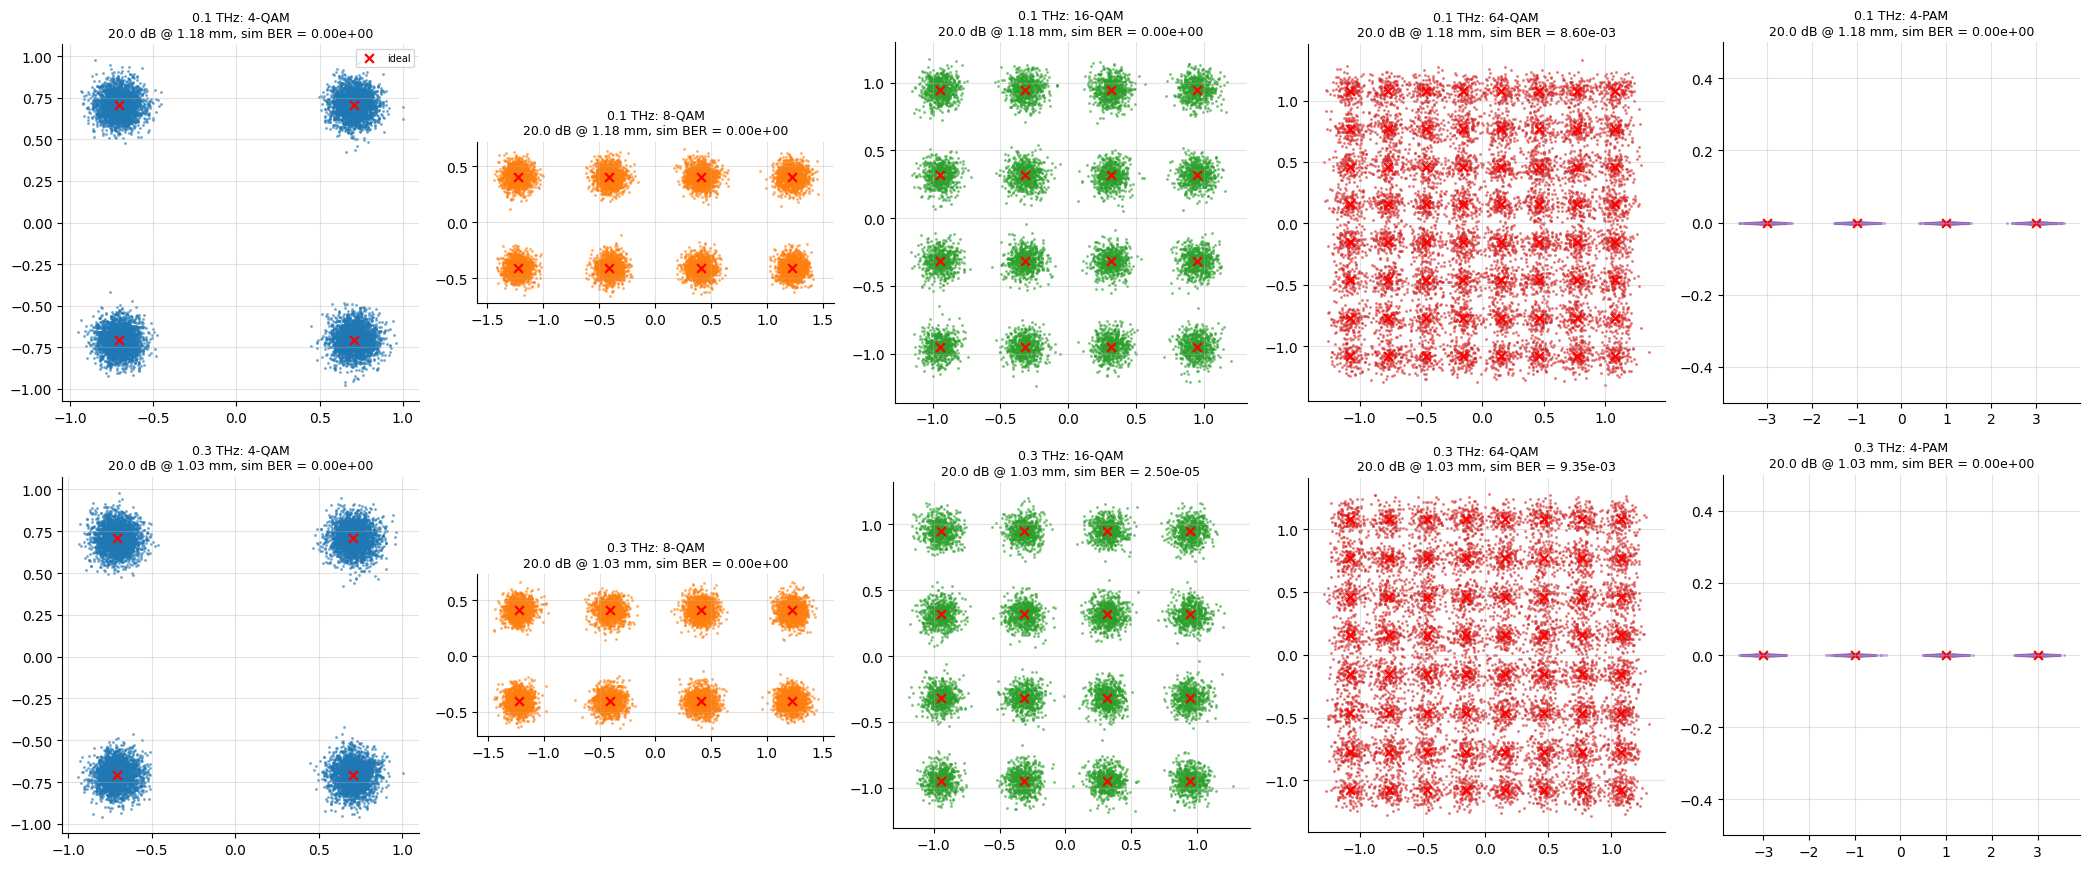

In [43]:
demo_results = {}      # (frequency, scheme) -> simulation result at the demo operating point
for fname, f in FREQS_HZ.items():
    snr_db = float(link_budget(f, D_DEMO_M[fname])["snr_db"])
    for name, cfg in SCHEMES.items():
        demo_results[(fname, name)] = simulate_link(cfg, snr_db)

fig, axes = plt.subplots(len(FREQS_HZ), len(SCHEMES), figsize=(4.2 * len(SCHEMES), 4.4 * len(FREQS_HZ)))
for r, fname in enumerate(FREQS_HZ):
    for c, (name, cfg) in enumerate(SCHEMES.items()):
        ax = axes[r, c]
        res = demo_results[(fname, name)]
        ax.scatter(res["rx_sym"].real, res["rx_sym"].imag, s=1.5, alpha=0.45, color=SCHEME_COLORS[name])
        ax.scatter(cfg["points"].real, cfg["points"].imag, color="red", marker="x", s=40, linewidths=1.6, label="ideal")
        ax.set_title(f"{fname}: {name}\n{res['snr_db']:.1f} dB @ {D_DEMO_M[fname]*1e3:.2f} mm, sim BER = {res['ber']:.2e}", fontsize=9)
        if cfg["is_one_dim"]:
            ax.set_ylim(-0.5, 0.5)
        else:
            ax.set_aspect("equal", "box")
        if r == 0 and c == 0:
            ax.legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

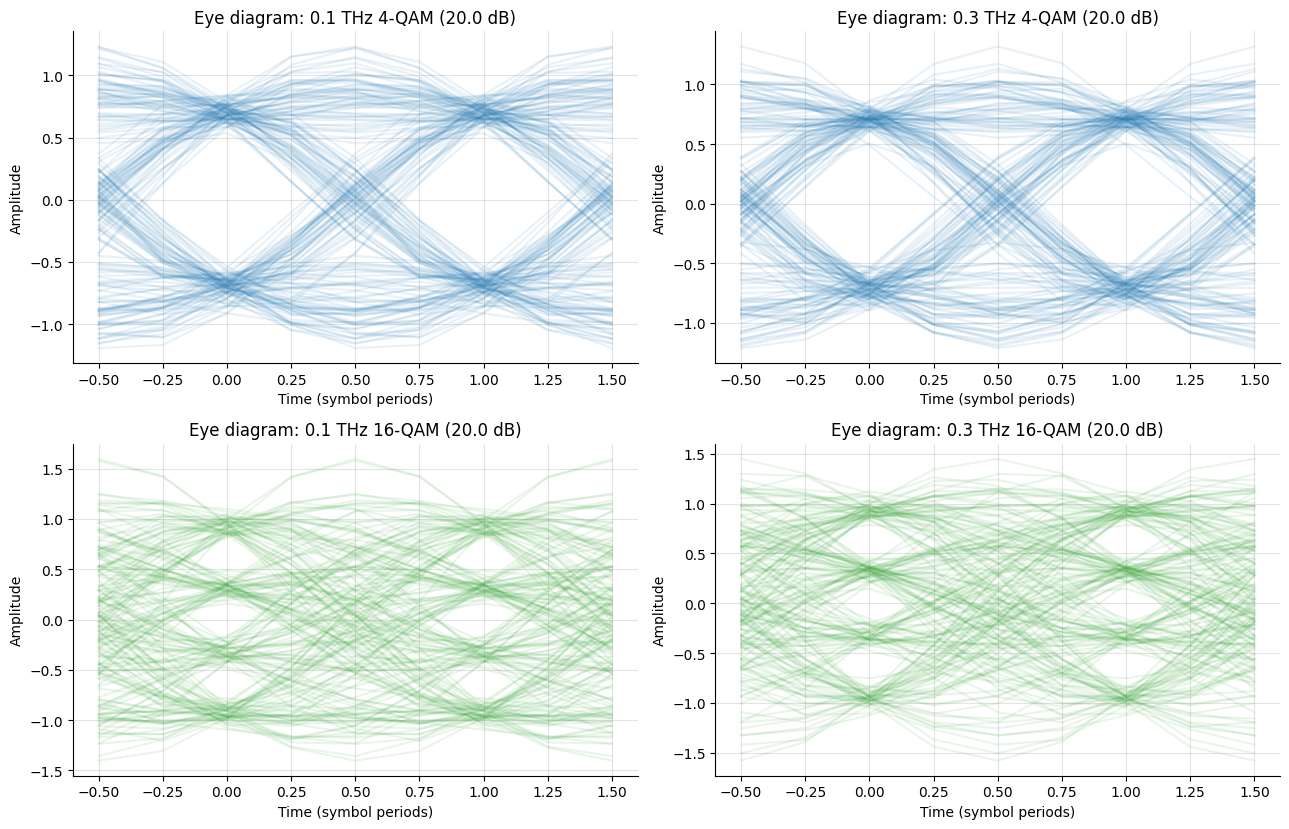

In [44]:
# Eye diagrams (I-channel, matched-filter output): rows = scheme, columns = frequency
n_traces, span = 200, 2 * sps
starts = DELAY - sps // 2 + sps * np.arange(5, 5 + n_traces)[:, None] + np.arange(span + 1)[None, :]
t = np.arange(span + 1) / sps - (sps // 2) / sps      # symbol periods; decision instants at t = 0 and 1

fig, axes = plt.subplots(len(EYE_SCHEMES), len(FREQS_HZ), figsize=(6.5 * len(FREQS_HZ), 4.2 * len(EYE_SCHEMES)), squeeze=False)
for r, scheme_key in enumerate(EYE_SCHEMES):
    for c, fname in enumerate(FREQS_HZ):
        ax = axes[r, c]
        res = demo_results[(fname, scheme_key)]
        ax.plot(t, np.real(res["rx_mf"][starts]).T, color=SCHEME_COLORS[scheme_key], alpha=0.1)
        ax.set(xlabel="Time (symbol periods)", ylabel="Amplitude",
               title=f"Eye diagram: {fname} {scheme_key} ({res['snr_db']:.1f} dB)")
plt.tight_layout()
plt.show()

## 10. Simulation vs theory validation
The Monte-Carlo engine (section 5) is swept over Eb/N0 for every scheme and overlaid on the theoretical curves
from the registry (section 3). BER versus Eb/N0 does not depend on carrier frequency, so one panel serves both frequencies.
Points with zero observed errors cannot be shown on a log axis and are omitted.
The theory uses the nearest-neighbour approximation, so a small gap at very low Eb/N0 (high BER) is expected.

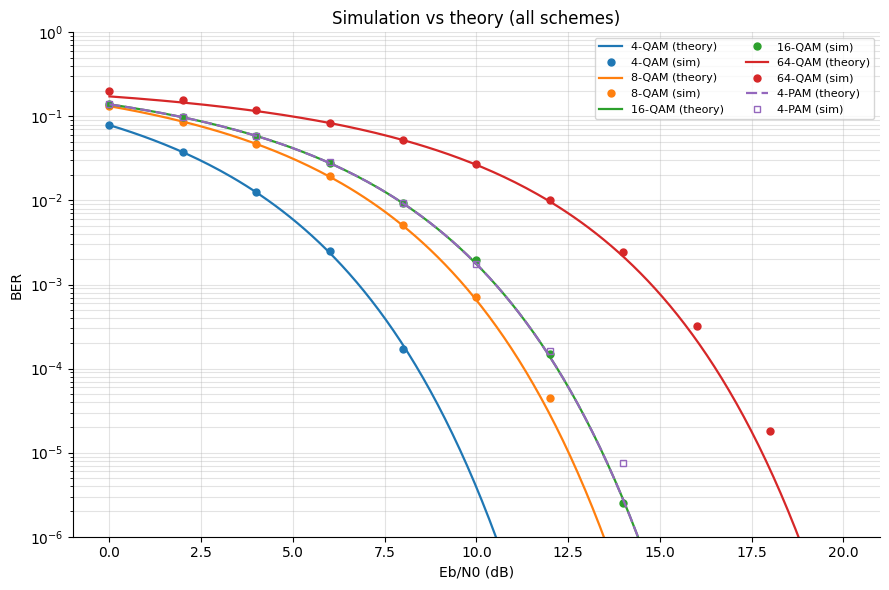

Points with >= 100 bit errors: sim/theory ratio  (1.00 = perfect)


,count,min,median,max
Modulation,,,,
16-QAM,7,0.995,1.012,1.112
4-PAM,6,0.991,1.000,1.020
4-QAM,4,0.998,1.005,1.059
64-QAM,9,1.011,1.055,1.481
8-QAM,6,0.999,1.011,1.086


In [45]:
validation_rows = []
fig, ax = plt.subplots(figsize=(9, 6))
ebn0_fine_db = np.linspace(0, 20, 200)
for name, cfg in SCHEMES.items():
    k = cfg["bits_per_symbol"]
    ax.plot(ebn0_fine_db, cfg["ber_func"](10 ** (ebn0_fine_db / 10)), lw=1.6, ls=SCHEME_LS[name], color=SCHEME_COLORS[name], label=f"{name} (theory)")
    sim = []
    for eb in ebn0_validation_db:
        res = simulate_link(cfg, eb + 10 * np.log10(k), n_symbols=num_symbols_ber)
        sim.append(res["ber"])
        validation_rows.append({"Modulation": name, "Eb/N0 (dB)": eb,
                                "Theory BER": float(cfg["ber_func"](10 ** (eb / 10))),
                                "Simulated BER": res["ber"], "Bit errors": res["bit_errors"]})
    sim = np.array(sim, dtype=float)
    sim[sim == 0] = np.nan
    ax.plot(ebn0_validation_db, sim, SCHEME_MARK[name], color=SCHEME_COLORS[name], ms=5, mfc="none" if name == PAM_NAME else None, label=f"{name} (sim)")
ax.set(yscale="log", ylim=(1e-6, 1), xlabel="Eb/N0 (dB)", ylabel="BER", title="Simulation vs theory (all schemes)")
ax.grid(True, which="both")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

df_validation = pd.DataFrame(validation_rows)
df_validation["Sim / theory"] = df_validation["Simulated BER"] / df_validation["Theory BER"]
good = df_validation[df_validation["Bit errors"] >= 100]        # enough errors for a meaningful ratio
print("Points with >= 100 bit errors: sim/theory ratio  (1.00 = perfect)")
display(good.groupby("Modulation")["Sim / theory"].agg(["count", "min", "median", "max"]).round(3))

## 11. Consolidated summary
One row per frequency and scheme: energy profile (section 6), link budget (section 4), theoretical BER at the reference and demo distances,
simulated BER at the demo distance (section 9), and the **maximum range** at `BER_TARGET` for the default gains.

In [46]:
# ---- helpers shared with the gain study (section 12) -----------------------
FINE_D_M = np.logspace(-6, -2, 4000)      # 1 um .. 10 mm search grid for the maximum range

def ber_at(freq_hz, scheme, d_m, g_tx_dbi, g_rx_dbi):
    """Theoretical BER at distance d (array ok) for given antenna gains."""
    snr = link_budget(freq_hz, d_m, g_tx_dbi, g_rx_dbi)["snr"]
    return scheme["ber_func"](snr / scheme["bits_per_symbol"])

def max_range_m(freq_hz, scheme, g_tx_dbi, g_rx_dbi, target=BER_TARGET):
    """Largest distance with theoretical BER <= target (BER rises monotonically with distance)."""
    ok = np.where(ber_at(freq_hz, scheme, FINE_D_M, g_tx_dbi, g_rx_dbi) <= target)[0]
    return float(FINE_D_M[ok[-1]]) if len(ok) else 0.0

summary_rows = []
for fname, f in FREQS_HZ.items():
    b_ref, b_demo = link_budget(f, D_REF_M), link_budget(f, D_DEMO_M[fname])
    for cfg, energy_row in zip(SCHEMES.values(), df_energy.to_dict("records")):
        k = cfg["bits_per_symbol"]
        summary_rows.append({
            "Frequency": fname, **energy_row,
            "SNR @ ref (dB)": float(b_ref["snr_db"]),
            "Theory BER @ ref": float(cfg["ber_func"](b_ref["snr"] / k)),
            "Demo d (mm)": D_DEMO_M[fname] * 1e3,
            "SNR @ demo (dB)": float(b_demo["snr_db"]),
            "Theory BER @ demo": float(cfg["ber_func"](b_demo["snr"] / k)),
            "Sim BER @ demo": demo_results[(fname, cfg["name"])]["ber"],
            f"Max range @ BER {BER_TARGET:g} (mm)": max_range_m(f, cfg, *gains(fname)) * 1e3,
        })
df_summary = pd.DataFrame(summary_rows)
with pd.option_context("display.float_format", "{:.3g}".format, "display.width", 250, "display.max_columns", 30):
    display(df_summary)

,Frequency,Modulation,Bits/Symbol,Data Rate (Gbps),Duration (ms),Energy Spent (mJ),SNR @ ref (dB),Theory BER @ ref,Demo d (mm),SNR @ demo (dB),Theory BER @ demo,Sim BER @ demo,Max range @ BER 0.001 (mm)
0,0.1 THz,4-QAM,2,2,33.6,0.671,99.2,0,1.18,20,7.62e-24,0,1.35
1,0.1 THz,8-QAM,3,3,22.4,0.447,99.2,0,1.18,20,3.24e-09,0,1.27
2,0.1 THz,16-QAM,4,4,16.8,0.336,99.2,0,1.18,20,2.9e-06,0,1.24
3,0.1 THz,64-QAM,6,6,11.2,0.224,99.2,0,1.18,20,0.00849,0.0086,1.14
4,0.1 THz,4-PAM,2,2,33.6,0.671,99.2,0,1.18,20,9.52e-11,0,1.29
5,0.3 THz,4-QAM,2,2,33.6,0.671,89.7,0,1.03,20,7.62e-24,0,1.19
6,0.3 THz,8-QAM,3,3,22.4,0.447,89.7,0,1.03,20,3.24e-09,0,1.12
7,0.3 THz,16-QAM,4,4,16.8,0.336,89.7,0,1.03,20,2.9e-06,2.5e-05,1.08
8,0.3 THz,64-QAM,6,6,11.2,0.224,89.7,0,1.03,20,0.00849,0.00935,0.983
9,0.3 THz,4-PAM,2,2,33.6,0.671,89.7,0,1.03,20,9.52e-11,0,1.13


## 12. Antenna-gain study
Here the gain is the variable. Because `Pr` depends on `G_tx + G_rx` only, the gains are applied at both ends
(`G_tx = G_rx = G`) unless stated otherwise. In every figure, **dashed or shaded** means *Friis not valid*
(`FSPL < G_tx + G_rx`, the formula would give `Pr > Pt`); **solid** means the budget is internally consistent.

What to look for: with `alpha` = 53 dB/mm, 10 dB of extra gain buys only about 0.3 mm of range (the budget slope is about 53 dB/mm plus the spreading term),
so gain helps far less here than in a low-loss link, and high gains mostly push the valid region beyond the usable range.

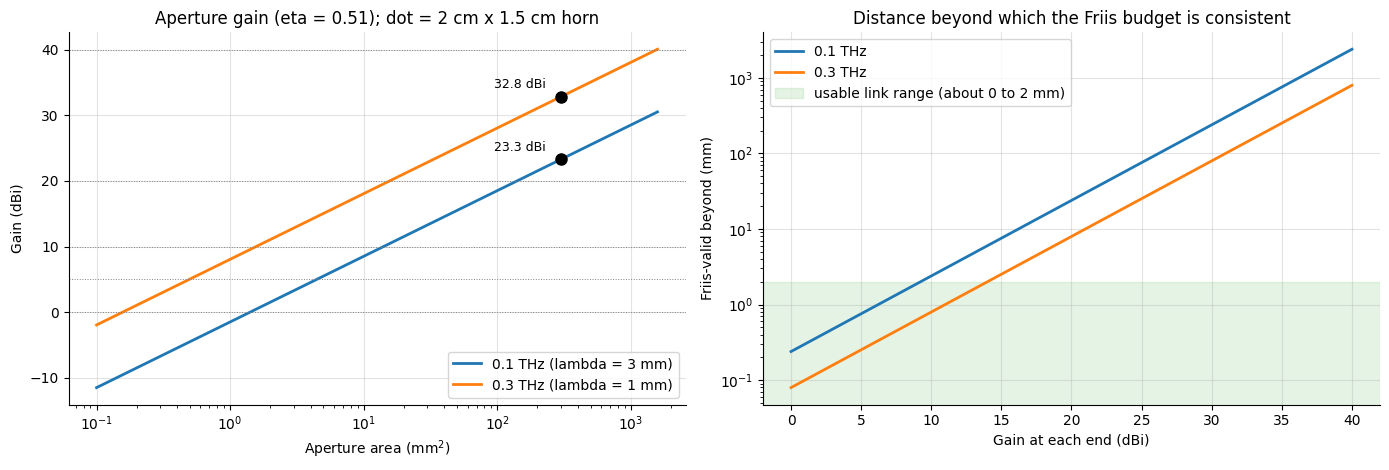

In [47]:
# ---- 12.1 Gain vs aperture area ---------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
areas_mm2 = np.logspace(-1, 3.2, 300)                         # 0.1 mm^2 .. ~1600 mm^2
for fname, f in FREQS_HZ.items():
    lam = wavelength(f)
    g = 10 * np.log10(4 * np.pi * APERTURE_EFFICIENCY * areas_mm2 * 1e-6 / lam ** 2)
    axes[0].plot(areas_mm2, g, lw=2, label=f"{fname} (lambda = {lam*1e3:g} mm)")
    axes[0].plot(APERTURE_A_M * APERTURE_B_M * 1e6, aperture_gain_dbi(f), "o", ms=8, color="k")
    axes[0].annotate(f"{aperture_gain_dbi(f):.1f} dBi", (APERTURE_A_M * APERTURE_B_M * 1e6, aperture_gain_dbi(f)),
                     textcoords="offset points", xytext=(-48, 6), fontsize=9)
for g_val in GAIN_STUDY_DBI:
    axes[0].axhline(g_val, color="grey", lw=0.7, ls=":")
axes[0].set(xscale="log", xlabel="Aperture area (mm$^2$)", ylabel="Gain (dBi)",
            title=f"Aperture gain (eta = {APERTURE_EFFICIENCY}); dot = 2 cm x 1.5 cm horn")
axes[0].legend()

for fname, f in FREQS_HZ.items():
    gs = np.arange(0, 41)
    axes[1].plot(gs, near_field_limit_m(f, gs, gs) * 1e3, lw=2, label=f"{fname}")
axes[1].axhspan(0, 2, color="tab:green", alpha=0.12, label="usable link range (about 0 to 2 mm)")
axes[1].set(yscale="log", xlabel="Gain at each end (dBi)", ylabel="Friis-valid beyond (mm)",
            title="Distance beyond which the Friis budget is consistent")
axes[1].legend()
plt.tight_layout()
plt.show()

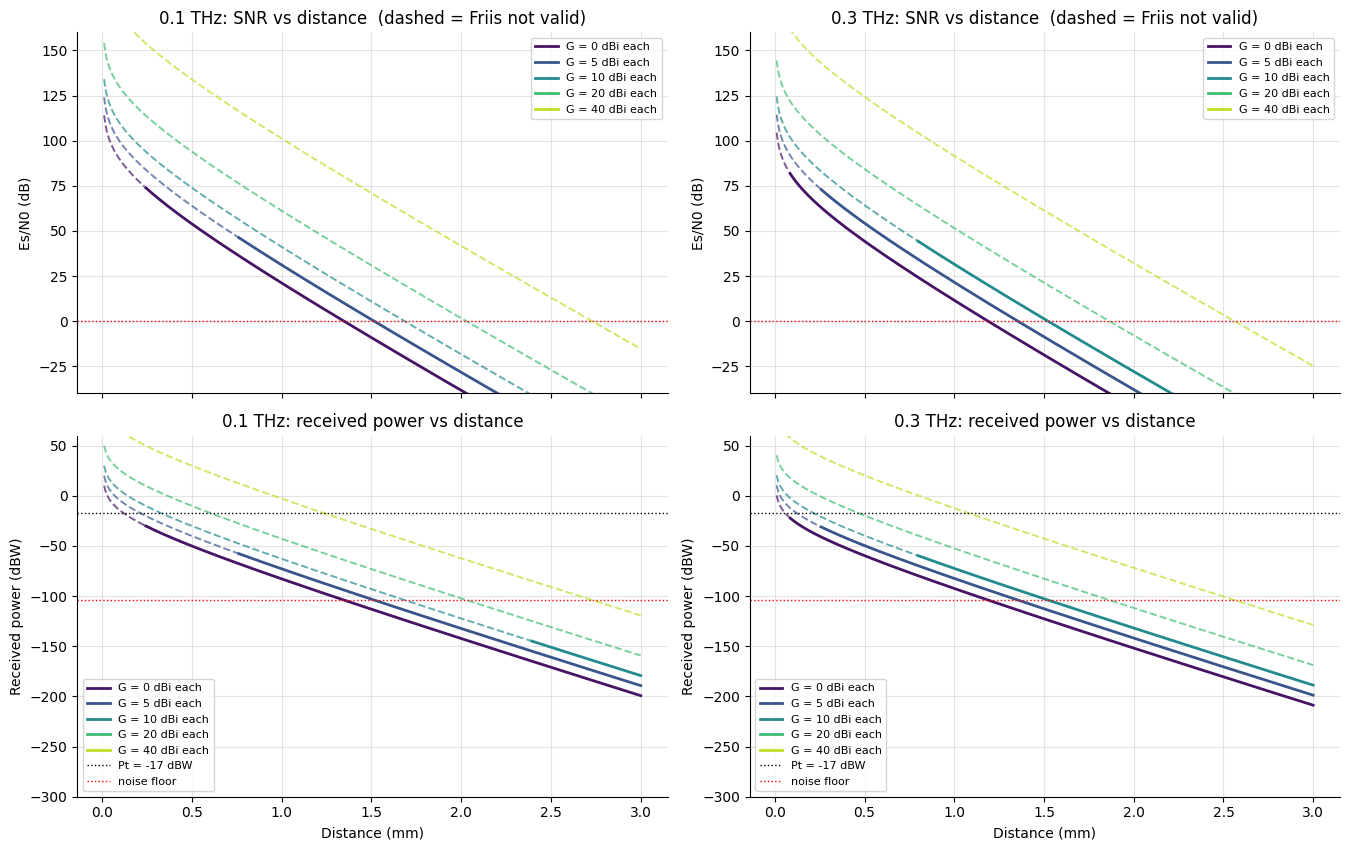

In [48]:
# ---- 12.2 SNR and received power vs distance for several gains -----------------
def plot_validity(ax, x_mm, y, d_nf_mm, color, label):
    """Solid where Friis is valid (d >= d_nf), dashed where it is not."""
    valid = x_mm >= d_nf_mm
    ax.plot(x_mm[~valid], y[~valid], color=color, ls="--", lw=1.4, alpha=0.7)
    ax.plot(x_mm[valid], y[valid], color=color, ls="-", lw=2, label=label)

gain_colors = plt.cm.viridis(np.linspace(0.05, 0.9, len(GAIN_STUDY_DBI)))
x_mm = DIST_SWEEP_M * 1e3
fig, axes = plt.subplots(2, len(FREQS_HZ), figsize=(6.8 * len(FREQS_HZ), 8.6), sharex=True)
for c, (fname, f) in enumerate(FREQS_HZ.items()):
    for g, col in zip(GAIN_STUDY_DBI, gain_colors):
        b = link_budget(f, DIST_SWEEP_M, g, g)
        d_nf = near_field_limit_m(f, g, g) * 1e3
        plot_validity(axes[0, c], x_mm, b["snr_db"], d_nf, col, f"G = {g} dBi each")
        plot_validity(axes[1, c], x_mm, b["pr_dbw"], d_nf, col, f"G = {g} dBi each")
    axes[0, c].axhline(0, color="red", ls=":", lw=1)
    axes[0, c].set(ylabel="Es/N0 (dB)", title=f"{fname}: SNR vs distance  (dashed = Friis not valid)", ylim=(-40, 160))
    axes[1, c].axhline(PT_DBW, color="k", ls=":", lw=1, label=f"Pt = {PT_DBW:.0f} dBW")
    axes[1, c].axhline(NOISE_FLOOR_DBW, color="red", ls=":", lw=1, label="noise floor")
    axes[1, c].set(xlabel="Distance (mm)", ylabel="Received power (dBW)", title=f"{fname}: received power vs distance", ylim=(-300, 60))
    axes[0, c].legend(fontsize=8)
    axes[1, c].legend(fontsize=8)
plt.tight_layout()
plt.show()

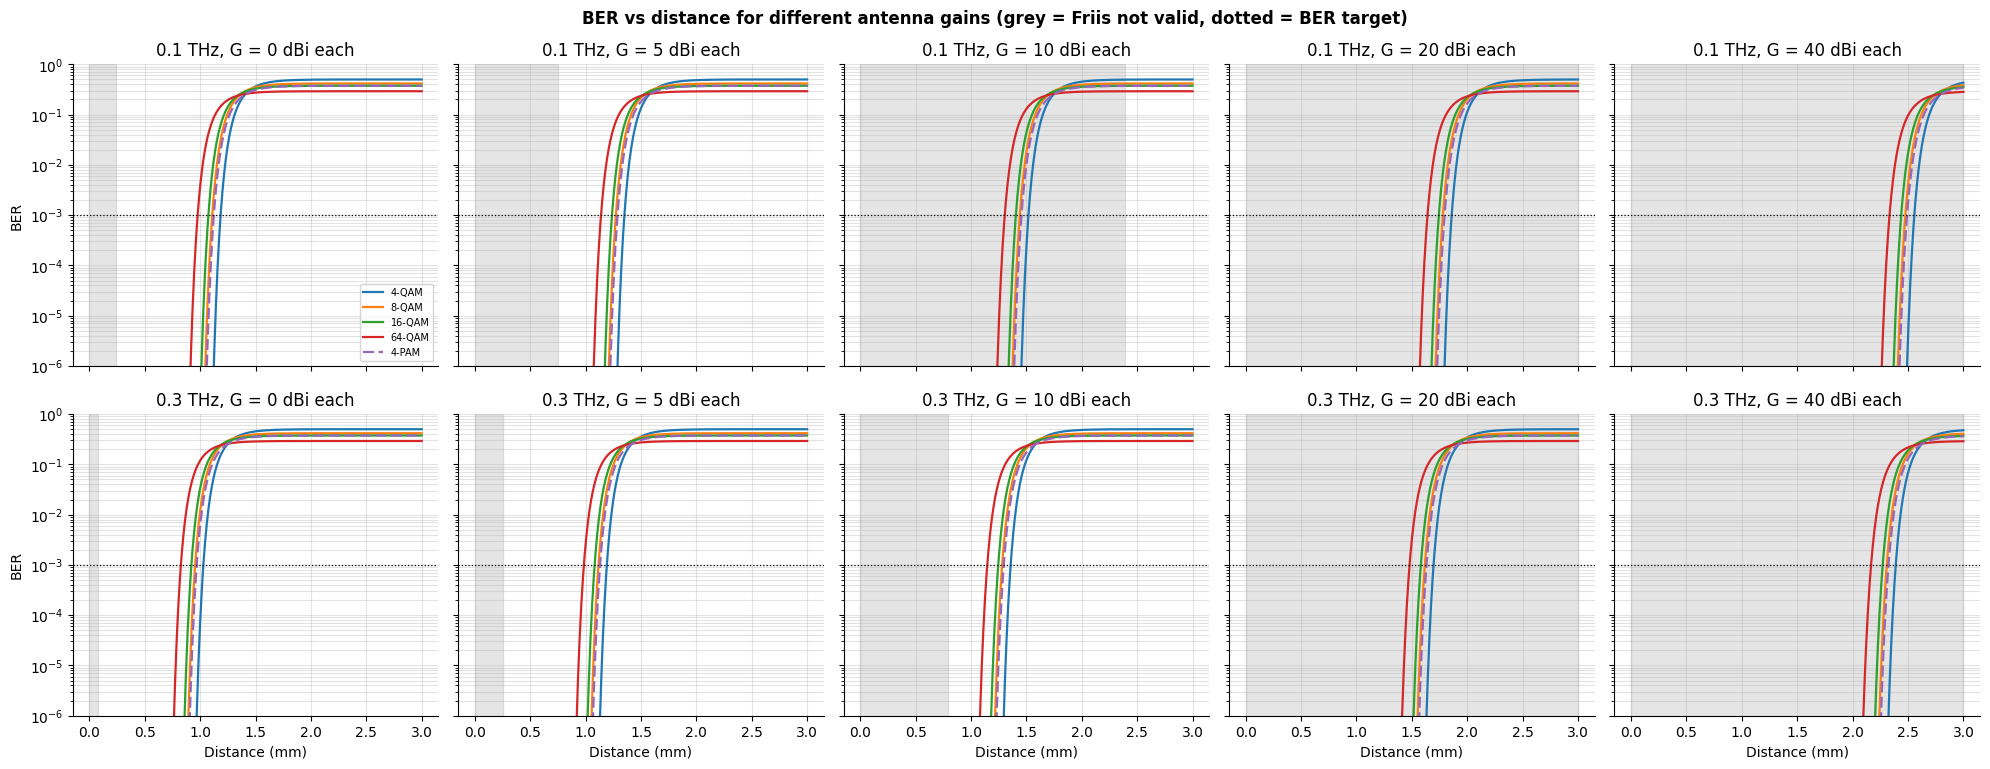

In [49]:
# ---- 12.3 BER vs distance for several gains (rows: frequency, columns: gain) --------
fig, axes = plt.subplots(len(FREQS_HZ), len(GAIN_STUDY_DBI), figsize=(4.0 * len(GAIN_STUDY_DBI), 3.9 * len(FREQS_HZ)),
                         sharey=True, sharex=True)
for r, (fname, f) in enumerate(FREQS_HZ.items()):
    for c, g in enumerate(GAIN_STUDY_DBI):
        ax = axes[r, c]
        for name, cfg in SCHEMES.items():
            ax.plot(x_mm, ber_at(f, cfg, DIST_SWEEP_M, g, g), color=SCHEME_COLORS[name], ls=SCHEME_LS[name], lw=1.6, label=name)
        d_nf = near_field_limit_m(f, g, g) * 1e3
        ax.axvspan(0, min(d_nf, x_mm.max()), color="grey", alpha=0.2)
        ax.axhline(BER_TARGET, color="k", ls=":", lw=0.9)
        ax.set(yscale="log", ylim=(1e-6, 1), title=f"{fname}, G = {g} dBi each")
        if r == len(FREQS_HZ) - 1: ax.set_xlabel("Distance (mm)")
        if c == 0: ax.set_ylabel("BER")
        ax.grid(True, which="both")
axes[0, 0].legend(fontsize=7)
fig.suptitle("BER vs distance for different antenna gains (grey = Friis not valid, dotted = BER target)", fontweight="bold")
plt.tight_layout()
plt.show()

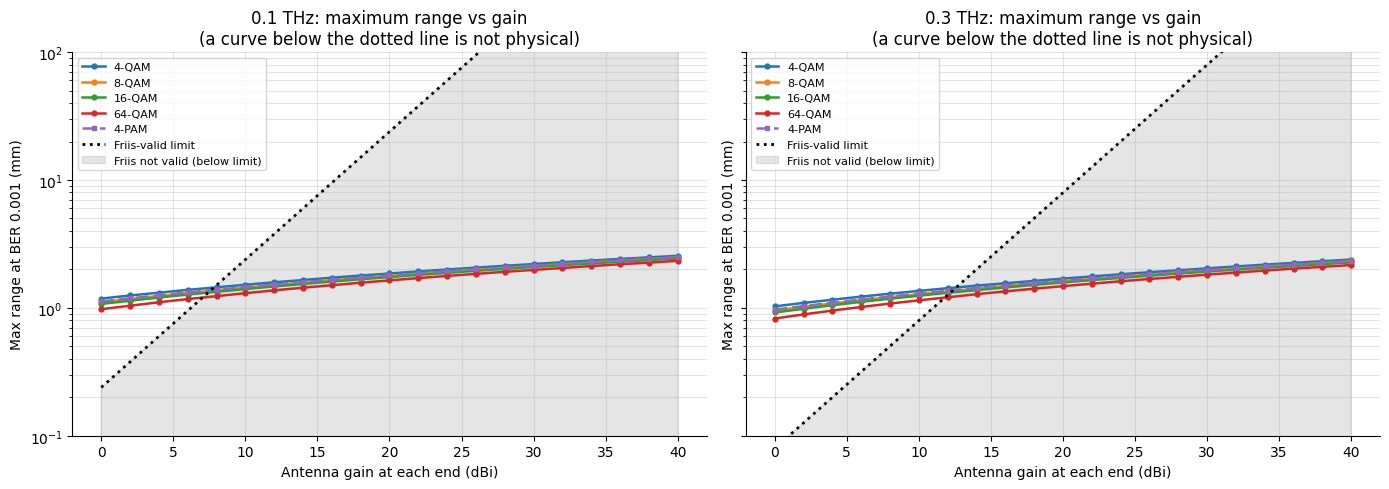

Maximum range (mm) at BER <= 0.001.   * = Friis not valid at that distance (treat as indicative only)


,Frequency,Modulation,G=0 dBi,G=5 dBi,G=10 dBi,G=20 dBi,G=40 dBi
0,0.1 THz,4-QAM,1.18,1.35,1.52*,1.86*,2.55*
1,0.1 THz,8-QAM,1.11,1.27,1.44*,1.78*,2.47*
2,0.1 THz,16-QAM,1.07,1.24,1.40*,1.74*,2.44*
3,0.1 THz,64-QAM,0.98,1.14,1.30*,1.64*,2.33*
4,0.1 THz,4-PAM,1.12,1.29,1.45*,1.79*,2.49*
5,0.3 THz,4-QAM,1.03,1.19,1.36,1.69*,2.39*
6,0.3 THz,8-QAM,0.95,1.12,1.28,1.62*,2.31*
7,0.3 THz,16-QAM,0.92,1.08,1.24,1.58*,2.27*
8,0.3 THz,64-QAM,0.83,0.98,1.14,1.48*,2.16*
9,0.3 THz,4-PAM,0.97,1.13,1.29,1.63*,2.32*


In [50]:
# ---- 12.4 Maximum range vs gain ---------------------------------------------------
GAIN_GRID_DBI = np.arange(0, 41, 2)
fig, axes = plt.subplots(1, len(FREQS_HZ), figsize=(7 * len(FREQS_HZ), 5), sharey=True)
for ax, (fname, f) in zip(axes, FREQS_HZ.items()):
    for name, cfg in SCHEMES.items():
        r_mm = np.array([max_range_m(f, cfg, g, g) for g in GAIN_GRID_DBI]) * 1e3
        ax.plot(GAIN_GRID_DBI, r_mm, SCHEME_MARK[name], ls=SCHEME_LS[name], ms=3.5, lw=1.8, color=SCHEME_COLORS[name], label=name)
    d_nf = near_field_limit_m(f, GAIN_GRID_DBI, GAIN_GRID_DBI) * 1e3
    ax.plot(GAIN_GRID_DBI, d_nf, "k:", lw=2, label="Friis-valid limit")
    ax.fill_between(GAIN_GRID_DBI, 1e-3, d_nf, color="grey", alpha=0.2, label="Friis not valid (below limit)")
    ax.set(yscale="log", ylim=(1e-1, 1e2), xlabel="Antenna gain at each end (dBi)", ylabel=f"Max range at BER {BER_TARGET:g} (mm)",
           title=f"{fname}: maximum range vs gain\n(a curve below the dotted line is not physical)")
    ax.grid(True, which="both")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# table: maximum range (mm) for the study gains
rows = []
for fname, f in FREQS_HZ.items():
    for name, cfg in SCHEMES.items():
        row = {"Frequency": fname, "Modulation": name}
        for g in GAIN_STUDY_DBI:
            r = max_range_m(f, cfg, g, g) * 1e3
            ok = r >= near_field_limit_m(f, g, g) * 1e3
            row[f"G={g} dBi"] = f"{r:.2f}" + ("" if ok else "*")
        rows.append(row)
df_gain_range = pd.DataFrame(rows)
print(f"Maximum range (mm) at BER <= {BER_TARGET:g}.   * = Friis not valid at that distance (treat as indicative only)")
display(df_gain_range)

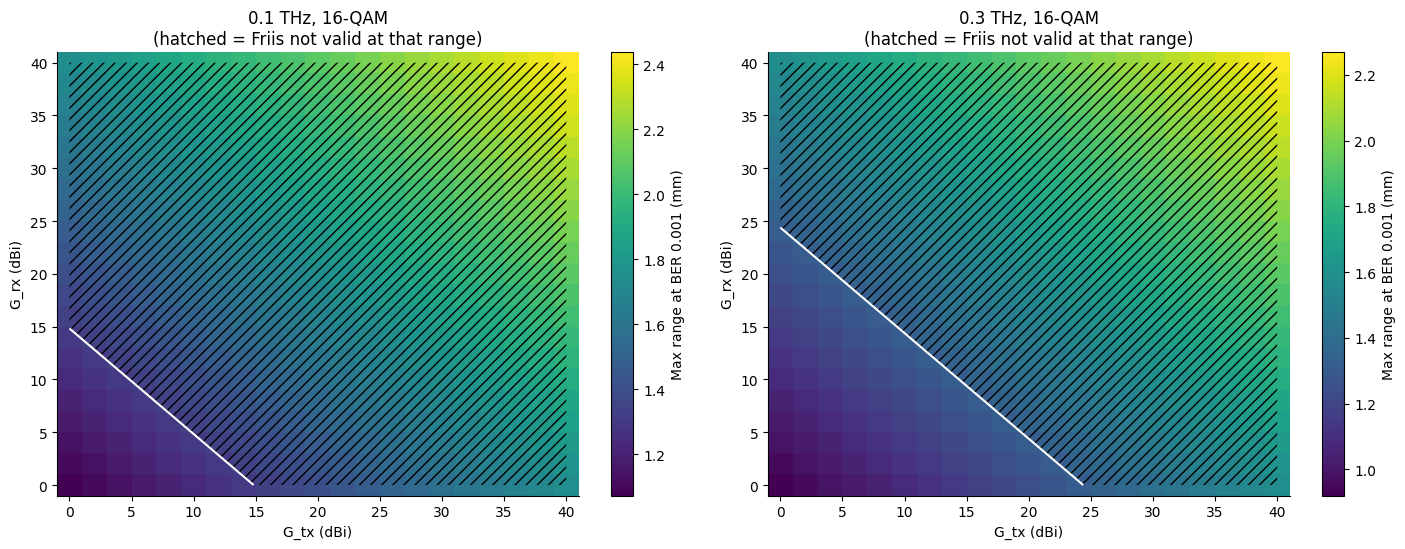

In [51]:
# ---- 12.5 Maximum-range heat-map over (G_tx, G_rx) --------------------------------------
# In the Friis budget only G_tx + G_rx matters, so contours are anti-diagonal; the map shows the trade-off between ends.
g_axis = np.arange(0, 41, 2)
fig, axes = plt.subplots(1, len(FREQS_HZ), figsize=(7.2 * len(FREQS_HZ), 5.6))
cfg = SCHEMES[HEATMAP_SCHEME]
for ax, (fname, f) in zip(axes, FREQS_HZ.items()):
    Z = np.array([[max_range_m(f, cfg, gt, gr) * 1e3 for gt in g_axis] for gr in g_axis])        # rows = G_rx, cols = G_tx
    GT, GR = np.meshgrid(g_axis, g_axis)
    V = (GT + GR) - fspl_db(Z * 1e-3, f)                  # > 0 : FSPL < G_tx + G_rx at the max range -> not valid
    im = ax.pcolormesh(GT, GR, Z, shading="nearest", cmap="viridis")
    ax.contourf(GT, GR, V, levels=[0, 1e9], colors="none", hatches=["///"])
    ax.contour(GT, GR, V, levels=[0], colors="white", linewidths=1.5)
    fig.colorbar(im, ax=ax, label=f"Max range at BER {BER_TARGET:g} (mm)")
    ax.set(xlabel="G_tx (dBi)", ylabel="G_rx (dBi)", title=f"{fname}, {HEATMAP_SCHEME}\n(hatched = Friis not valid at that range)")
    ax.grid(False)
plt.tight_layout()
plt.show()

### How to use this notebook
* Antenna gains are per frequency (`GAINS_DBI`, from `ch.GAIN_DBI_BY_FREQ`: 0.1 THz 5/5 dBi, 0.3 THz 10/10 dBi). Set `LEGACY_GAINS = True` (section 1) for 5/5 dBi at both frequencies, the setting of the earlier saved outputs; sections 2 to 11 follow.
* The link budget and modulation engine are imported from `dwf2d/channels.py`, which the DWF (`build_2D_dwf.py integrated_demo`) uses too.
* Set `GAIN_STUDY_DBI` to choose which gains appear in the section-12 figures.
* Set `NOISE_MODE = "notebook"` to return to the original fixed noise values (1 mW floor, 1e-10 W/Hz PSD).
* Set `PAM_BITS` to change the PAM order; `EYE_SCHEMES` / `HEATMAP_SCHEME` choose which schemes appear in the eye and heat-map figures.
* To force a demo distance instead of solving it from `DEMO_TARGET_SNR_DB`, fill `D_DEMO_OVERRIDE_M`.

# Energy profile of slave node


## IoT Node Energy Profile Design
Based on the system specifications of our IoT node, this section models the timing profile, operational parameters, and cumulative energy consumption across the core hardware components (Camera, MCU, PSRAM, and MPPT during the active-transmit cycle).

> **Values used by the DWF.** The table below is the datasheet view. The numbers the model uses live in `slave_config.py` (`EVENT_COMPONENTS`, `EVENT_DURATIONS`) and are read by `slave_load.event_profile()`, shared with `build_2D_dwf.py integrated_demo`: camera 0.30 W x 0.5 s = 0.15 J, PSRAM write = read = 10.5 ms (the read runs inside the TX window), $t_{tx}$ = 8 MiB / (1 Gsps x 4 bit) = 16.777 ms, MCU active $t_{camera} + t_{write} + t_{tx}$ = 527.3 ms, photomixer 200 mW electrical while transmitting. The MPPT's 330 mW is its input rating (the S5 cap), not a load.

### 1. Component Operational Specifications

| Component Name | Operation Mode | Power Consumption | Energy Calculation | Duration / Time |
| :--- | :--- | :--- | :--- | :--- |
| **Camera Module** (13 MP w/ HW JPEG) | Active (Capture) | $280\text{ mW } (0.28\text{ W})$ | $0.15\text{ J } (0.3\text{ W} \times 0.5\text{ s})$ | $0.5\text{ s}$ per capture |
| | Deep Sleep | $0.01\text{ mW } (10\ \mu\text{W})$ | $0.01\text{ mW} \times t_{\text{sleep}}$ | Between captures ($t_{\text{sleep}}$) |
| **Microcontroller** | Active | $60\text{ mW } (0.06\text{ W})$ | $60\text{ mW} \times t_{\text{active}}$ | Active duration ($t_{\text{active}}$) |
| | Deep Sleep | $0.016\text{ mW } (16\ \mu\text{W})$ | $0.016\text{ mW} \times t_{\text{sleep\_tx}}$ | Idle/Sleep duration ($t_{\text{sleep\_tx}}$) |
| **MPPT** | Active Charging | $330\text{ mW } (0.33\text{ W})$ | $\text{Input Power} \times t_{\text{charge}}$ | Charging time ($t_{\text{charge}}$) |
| | Quiescent | $960\text{ nW } (0.96\ \mu\text{W})$ | $960\text{ nW} \times t_{\text{quiescent}}$ | Operating duration ($t_{\text{quiescent}}$) |
| | Sleep Mode | $1.44\ \mu\text{W } (V_{\text{storage}} \times 480\text{ nA})$ | $\text{Sleep Power} \times t_{\text{sleep}}$ | Sleep duration ($t_{\text{sleep}}$) |
| **APS12808L PSRAM** | Active Mode (200 MHz) | $39.6\text{ mW } (22\text{ mA} @ 1.8\text{V})$ | $39.6\text{ mW} \times t_{\text{active\_mem}}$ | Read/Write duration ($t_{\text{active\_mem}}$) |
| | Standby Mode (Data Retained) | $237.6\ \mu\text{W } (132\ \mu\text{A} @ 1.8\text{V})$ | $237.6\ \mu\text{W} \times t_{\text{standby}}$ | Standby duration ($t_{\text{standby}}$) |
| | Deep Power Down (25°C) | $25.2\ \mu\text{W } (14\ \mu\text{A} @ 1.8\text{V})$ | $25.2\ \mu\text{W} \times t_{\text{dpd}}$ | Power down duration ($t_{\text{dpd}}$) |
| | Deep Power Down (Typ Max) | $54\ \mu\text{W } (30\ \mu\text{A} @ 1.8\text{V})$ | $54\ \mu\text{W} \times t_{\text{dpd}}$ | Power down duration ($t_{\text{dpd}}$) |

### 2. Microcontroller Active Duration & Pipeline Breakdown
The total active mode duration ($t_{\text{active}}$) of the microcontroller is determined by the specific modulation scheme's transmission time ($t_{\text{tx}}$) plus the camera and memory processing overhead:

$$t_{\text{active}} = t_{\text{camera}} + t_{\text{mem}} + t_{\text{tx}}$$

* **Camera Readout ($t_{\text{camera}}$):** $500\text{ ms } (0.5\text{ s})$
* **PSRAM Storage ($t_{\text{mem}}$):** $10.5\text{ ms } (0.0105\text{ s})$ — Time to write 4MB frame at 200 MHz
* **Modulation Transmission ($t_{\text{tx}}$):** $17\text{ ms } (0.017\text{ s})$ — Based on 16-QAM modulation duration

Total MCU Active Time:
$$t_{\text{active}} = 500\text{ ms} + 10.5\text{ ms} + 17\text{ ms} = \mathbf{527.5\text{ ms}} \quad (\mathbf{0.5275\text{ s}})$$

### 3. Active Cycle Energy Equations
Energy consumption per component during the active execution cycle ($t_{\text{tx}} = 17\text{ ms}$):

$$\begin{aligned}
E_{\text{MCU}} &= 60\text{ mW} \times 0.5275\text{ s} = \mathbf{31.65\text{ mJ}}\\
E_{\text{Camera}} &= 280\text{ mW} \times 0.500\text{ s} = \mathbf{140.00\text{ mJ}}\\
E_{\text{PSRAM}} &= 39.6\text{ mW} \times 0.0105\text{ s} = \mathbf{0.416\text{ mJ}}\\
E_{\text{MCU\_Tx\_Only}} &= 60\text{ mW} \times 0.017\text{ s} = \mathbf{1.02\text{ mJ}}
\end{aligned}$$


,Component,Active Power (mW),Sleep Power (mW),Active Duration (ms),Active Energy (mJ),Energy Share (%)
0,Camera Module,280.0,0.01000,500.0,140.0000,40.052549
1,Microcontroller,60.0,0.01600,527.5,31.6500,9.054737
2,APS12808L PSRAM,39.6,0.23760,10.5,0.4158,0.118956
3,MPPT Circuit,330.0,0.00144,527.5,174.0750,49.801053
4,Photonic-Photomixer,200.0,0.00100,17.0,3.4000,0.972705


Total Active Energy consumed per Cycle: 349.540800 mJ


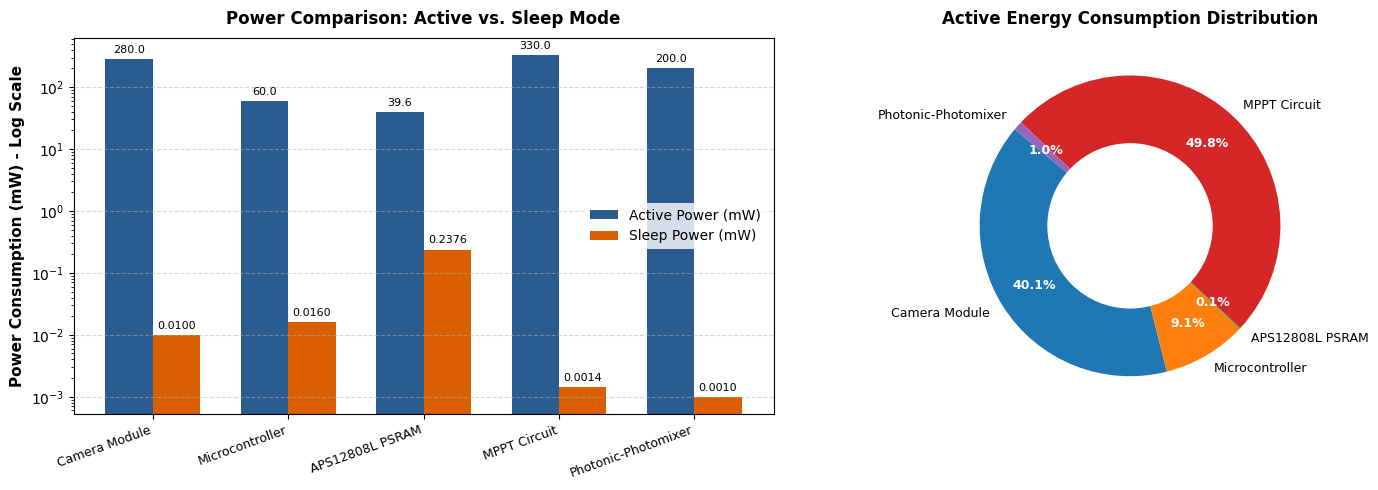

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display
import slave_config as scfg            # the slave's single source of truth (STAGE 6 block)
import slave_load                      # event-based load model shared with the DWF (integrated_demo)

# --- 13.1 Component Power & Timing Definitions (slave_config.EVENT_COMPONENTS / EVENT_DURATIONS) ---
ev = slave_load.event_profile([1], psram_state=scfg.PSRAM_SILENT_STATE)   # ONE event slot (tau = 60 s)
comp = {row["key"]: row for row in scfg.EVENT_COMPONENTS}
t_tx = ev["t_tx"]                     # THz burst: 8 MiB / (R_s x 4 bit) = 16.777216 ms (16-QAM, 1 Gsps)
t_act = {k: float(ev["t_active"][k][0]) for k in ev["overhead_keys"]}     # active time per event (s)
sleep_W = {k: (r["sleep_W"][scfg.PSRAM_SILENT_STATE] if isinstance(r["sleep_W"], dict) else r["sleep_W"])
           for k, r in comp.items()}

# --- 13.2 Energy Calculations (mJ) ---  active energy per event = P_active x t_active
e_active = {k: comp[k]["active_W"] * t_act[k] * 1000 for k in ev["overhead_keys"]}
total_energy_mj = sum(e_active.values())

# --- 13.3 Summary Dataframe ---
names = {"camera": "Camera Module", "mcu": "Microcontroller", "flash": "APS12808L PSRAM", "mppt": "MPPT Circuit",
         "photomixer": "Photonic-Photomixer"}
profile_data = []
for k in ev["overhead_keys"]:
    # MPPT: only its quiescent / sleep draw is a load (the 330 mW is its INPUT rating, see the note below)
    p_act = scfg.POWERS["mppt_quiescent_W"] if k == "mppt" else comp[k]["active_W"]
    profile_data.append({
        "Component": names.get(k, k),
        "Active Power (mW)": p_act * 1000,
        "Sleep Power (mW)": sleep_W[k] * 1000,
        "Active Duration (ms)": t_act[k] * 1000,
        "Active Energy (mJ)": e_active[k],
        "Energy Share (%)": (e_active[k] / total_energy_mj) * 100
    })

df_profile = pd.DataFrame(profile_data)
display(df_profile.round(6))
print(f"Total Active Energy consumed per Cycle: {total_energy_mj:.6f} mJ")
print(f"Per 60 s slot (slave_load.event_profile, PSRAM {scfg.PSRAM_SILENT_STATE} when idle): event slot "
      f"{ev['c'][0] * 1e3:.3f} mJ non-TX + photomixer burst up to {ev['x_cap'] * 1e3:.4f} mJ "
      f"(floor {ev['x_min'] * 1e3:.5f} mJ = 1 mW radiated); sleep slot "
      f"{slave_load.event_profile([0], psram_state=scfg.PSRAM_SILENT_STATE)['c'][0] * 1e3:.3f} mJ")
print(f"Note: MPPT input rating {scfg.POWERS['mppt_in_V']:g} V x {scfg.POWERS['mppt_in_I_max_A'] * 1e3:g} mA = "
      f"{scfg.POWERS['mppt_in_V'] * scfg.POWERS['mppt_in_I_max_A'] * 1e3:.0f} mW is the cap on what it can store "
      f"(S5: {scfg.POWERS['mppt_in_V'] * scfg.POWERS['mppt_in_I_max_A'] * scfg.MPPT_EFF * 60:.2f} J per slot at "
      f"{scfg.MPPT_EFF:.0%}), not a load; only its quiescent / sleep draw is.")

# --- 13.4 Data Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=100)

components = df_profile["Component"]
active_power = df_profile["Active Power (mW)"]
sleep_power = df_profile["Sleep Power (mW)"]
energy_share = df_profile["Active Energy (mJ)"]

# Plot 1: Active Power vs. Sleep Power (Log Scale)
x = np.arange(len(components))
width = 0.35

rects1 = axes[0].bar(x - width/2, active_power, width, label='Active Power (mW)', color='#2b5c8f')
rects2 = axes[0].bar(x + width/2, sleep_power, width, label='Sleep Power (mW)', color='#d95f02')

axes[0].set_yscale('log')
axes[0].set_ylabel('Power Consumption (mW) - Log Scale', fontsize=11, fontweight='bold')
axes[0].set_title('Power Comparison: Active vs. Sleep Mode', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xticks(x)
axes[0].set_xticklabels(components, rotation=20, ha='right', fontsize=9)
axes[0].legend(frameon=True, facecolor='white', edgecolor='none')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Value Labels for Plot 1
for rect in rects1:
    height = rect.get_height()
    axes[0].annotate(f'{height:.1f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=8)

for rect in rects2:
    height = rect.get_height()
    axes[0].annotate(f'{height:.4f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=8)

# Plot 2: Active Energy Distribution (Donut Chart)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
wedges, texts, autotexts = axes[1].pie(
    energy_share,
    labels=components,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    textprops=dict(fontsize=9)
)

# Draw center circle for donut plot
centre_circle = plt.Circle((0,0), 0.55, fc='white')
axes[1].add_artist(centre_circle)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_weight('bold')

axes[1].set_title('Active Energy Consumption Distribution', fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()